## Лабораторная работа №1 | Вариант 5

Выполнил: Белков Артём М8О-310БВ-24

### 1. Numpy

In [9]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [ ]:
np.eye(3)

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

2. Создайте кастомный dtype который описывает цвет состоящий из 4х unsigned bytes(RGBA пиксель)

In [ ]:
RGBA_type = np.dtype(
    [
    ('R', np.uint8),
    ('G', np.uint8),
    ('B', np.uint8),
    ('A', np.uint8)
    ]
)
pixel = np.array([(255, 255, 255, 255)], dtype=RGBA_type)
print(pixel)

[(255, 255, 255, 255)]


3. Как игнорировать все numpy warnings(не рекомендуем к использованию)?

In [ ]:
np.seterr(all='ignore')

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

4. Создайте случайный вектор размера 10 и отсортируйте его

In [ ]:
arr = np.random.randint(1, 100, 10)
arr_sorted = np.sort(arr)
print(arr_sorted)
print(arr)

[15 42 47 59 60 62 62 62 80 92]
[59 42 92 60 80 15 62 62 47 62]


5. Создайте read-only массив(неизменяемый)

In [ ]:
arr = np.array([1, 2, 3, 4, 5])
arr.flags.writeable=False
print(arr)

[1 2 3 4 5]


6. Рассмотрим случайную матрицу размером 10х2, представляющую декартовы координаты, преобразуем их в полярные координаты

In [10]:
np.random.seed(42)
arr = np.random.rand(10, 2)
print(arr)
# r = sqrt(x^2 + y^2)
# phi = arctg(y/x)
x = arr[:, :1]
y = arr[:, 1:]
r = np.sqrt(x**2 + y**2)
phi = np.arctan2(y, x)

polar = np.column_stack((r, phi))
print(polar)

[[0.37454012 0.95071431]
 [0.73199394 0.59865848]
 [0.15601864 0.15599452]
 [0.05808361 0.86617615]
 [0.60111501 0.70807258]
 [0.02058449 0.96990985]
 [0.83244264 0.21233911]
 [0.18182497 0.18340451]
 [0.30424224 0.52475643]
 [0.43194502 0.29122914]]
[[1.02183071 1.19551066]
 [0.94562525 0.68552846]
 [0.22062662 0.78532086]
 [0.86812143 1.50383906]
 [0.9288197  0.86691479]
 [0.97012826 1.54957641]
 [0.85909758 0.24975369]
 [0.25825866 0.78972293]
 [0.60657453 1.04537865]
 [0.52095193 0.59321867]]


7. Создайте структурированный массив с координатами x и y, охватывающий область [0,1]x[0,1]

In [ ]:
my_type = np.dtype([('x', np.float64), ('y', np.float64)])

n = 3

x = np.linspace(0, 1, n)
y = np.linspace(0, 1, n)
arr = np.empty((n, n), dtype=my_type)
arr['x'] = x[np.newaxis, :]
arr['y'] = y[:, np.newaxis]
print(arr['x'])
print()
print(arr['y'])

[[0.  0.5 1. ]
 [0.  0.5 1. ]
 [0.  0.5 1. ]]

[[0.  0.  0. ]
 [0.5 0.5 0.5]
 [1.  1.  1. ]]


8. Учитывая два массива X и Y, постройте матрицу Коши $C$ ($C_{ij} =\frac{1}{x_i - y_j}$)

In [ ]:
x = np.random.normal(size=(5))
y = np.random.normal(size=(5))

C_ij = 1.0 / (x[:, np.newaxis] - y[np.newaxis, :])
print(C_ij)


[[-1.27055953 -0.92561797  2.42767315 -2.13470685 -0.8898747 ]
 [ 1.85177081  4.05319202  0.57504461  1.16464593  4.91824057]
 [-1.46574315 -1.02506039  1.9352687  -2.74996228 -0.98140564]
 [-0.84279554 -0.67575243 80.35688177 -1.15217863 -0.65650127]
 [ 0.59121744  0.7152459   0.34597324  0.49750464  0.73815655]]


9. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [ ]:
# в общем... видимо numpy не позволяет
# менять dtype для существующего массива
# так что остаётся
# только astype, который конвертирует конечно, но создаёт новый массив
arr = np.array([1, 2, 3], dtype=float)
old = arr
# можно было бы сделать:
# old = arr.copy()
# old.dtype = np.int32
# но там был бы мусор, а не тот результат, который мы хотим

print(arr, arr.dtype)
old_id = id(arr)

arr = arr.astype(np.int32)
new_id = id(arr)
print(arr, arr.dtype)
print(old is arr)
print(old_id == new_id)

[1. 2. 3.] float64
[1 2 3] int32
False
False


10. Как случайно заменить p элементов в 2D массиве?

In [ ]:

arr = np.arange(9).reshape(3, 3)
print(arr)
print()
p = 3
flat_idx = np.random.choice(arr.size, size=p, replace=False)
arr.flat[flat_idx] = 67

print(arr)


[[0 1 2]
 [3 4 5]
 [6 7 8]]

[[ 0  1 67]
 [ 3 67  5]
 [ 6  7 67]]


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом

Классический начальный набор данных - данные пассажиров титаника.

Файл: `data.csv`

```
PassangerId - уникальный номер пассажира
Survived - выжил человек или нет
Pclass - класс обслуживания
Name - имя человека, обращение к ней/нему
Sex - пол человека
Age - возраст на момент крушения
SibSp - количество братьев и сестер / супругов на борту "Титаника"
Parch - количество родителей / детей на борту "Титаника"
Ticket - номер билета
Fare - стоимость проезда для пассажиров
Cabin - каюта
Embarked - причал отбытия. C = Cherbourg Q = Queenstown S = Southampton
```

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('data.csv')
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


1. Узнайте сколько было на борту человек

In [ ]:
total_people = df.shape[0]
total_people

891

2. Какой медианный и средний возраста пассажиров

In [ ]:
print(df['Age'].mean()) # средний
print(df['Age'].median()) # медианный

29.69911764705882
28.0


3. Посчитайте процент выживаемости детей(до 16 лет) и взрослых

In [ ]:
# Взрослых мы с 16 лет считаем? или с 18?
is_child = df['Age'].lt(16)
is_adult = df['Age'].ge(18)
# is_adult = df['Age'].ge(16)
child_survival = df[is_child]['Survived'].mean() * 100
adult_survival = df[is_adult]['Survived'].mean() * 100

print(f'{child_survival:.2f}% выживаемость детей')
print(f'{adult_survival:.2f}% выживаемость взрослых')

59.04% выживаемость детей
38.10% выживаемость взрослых


4. Верна ли гипотеза, что женщины и дети сажались в шлюпки первыми и выживали больше?

In [ ]:
is_women_or_child = (df['Age'].lt(16)) | ((df['Age'].gt(18)) & ((df['Sex']) == 'female'))

# не женщины и дети = мужчины
is_others = (df['Sex'] == 'male') & (df['Age'] >= 18)

women_or_child_survival = df[is_women_or_child]['Survived'].mean() * 100
others_survival = df[is_others]['Survived'].mean() * 100


print(f'Процент выживаемости женщин и детей = {women_or_child_survival:.2f}%')
print(f'Процент выживаемости остальных = {others_survival:.2f}%')

Процент выживаемости женщин и детей = 72.46%
Процент выживаемости остальных = 17.72%


5. Зависит ли выживаемость от класса обслуживания?

In [ ]:
df.groupby('Pclass')['Survived'].mean() * 100
# Чем выше класс обслуживания, тем выше шанс выживания
# Вывод: хотите жить - будьте богатыми

,Survived
Pclass,
1,62.962963
2,47.282609
3,24.236253


6. Посчитайте средний возраст умерших женщин и мужчин

In [4]:
is_dead = df['Survived'].eq(0)

mens_dead_mean_age = df[(df['Sex'] == 'male')  & df['Survived'].eq(0)]['Age'].mean()
print(f'{mens_dead_mean_age:.2f} - средний возраст умерших мужчин')

women_dead_mean_age = df[(df['Sex'] == 'female') & df['Survived'].eq(0)]['Age'].mean()
print(f'{women_dead_mean_age:.2f} - средний возраст умерших женщин')

31.62 - средний возраст умерших мужчин
25.05 - средний возраст умерших женщин


7. Различается ли процент выживаемости пассажиров с хотя бы одним родственником на борту и одиночек?

In [ ]:
is_alone = (df['Parch'] == 0) & (df['SibSp'] == 0)

res = df.groupby(is_alone)['Survived'].mean() * 100
print(f'Процент выживаемости пассажиров-одиночек = {res[True]:.2f}%')
print(f'Процент выживаемости пассажиров с хотя бы одним родственником = {res[False]:.2f}%')
# Если есть хотя бы один родственник, то процент выживаемости на целых 20% больше

Процент выживаемости пассажиров-одиночек = 30.35%
Процент выживаемости пассажиров с хотя бы одним родственником = 50.56%


8. Различается ли средняя стоимость билета у умерших и выживших пассажиров?

In [ ]:
df.groupby('Survived')['Fare'].mean()
# Различается:
# средняя стоимость билета у выживших чуть более чем в 2 раза выше, чем у погибших

,Fare
Survived,
0,22.117887
1,48.395408


9. Выведите максимальный и минимальный возраст выживших пассажиров во 2 классе обслуживания

In [ ]:
res = df[(df['Pclass'] == 2) & (df['Survived'] == 1)]['Age'].agg(['min', 'max'])
res

,Age
min,0.67
max,62.00


10. Подтвердите или опровергните гипотезу: молодым мужчинам(от 18 лет) выжить легче, чем более взрослым

In [ ]:
# Прошу прощения, а можно уточняющий вопрос, когда в данном случае мужчина считается более взрослым? 25? 30? 35? 60?
# У нас в стране молодёжь - люди до 35 лет! (а сейчас хотят вообще до 40 поднять)
# Как будто есть небольшая неточность в постановке задачи
# Давайте тогда ни вам ни мне - условимся на 30 годах взрослости

is_young_man = (df['Sex'] == 'male') & (df['Age'] >= 18) & (df['Age'] < 30)
is_adult_man = (df['Sex'] =='male') & (df['Age'] >= 30)

adult_survival_rate = df[is_adult_man]['Survived'].mean() * 100
young_survival_rate = df[is_young_man]['Survived'].mean() * 100

print(f'Процент выживаемости взрослых мужчин (30+ лет) = {adult_survival_rate:.2f}%')
print(f'Процент выживаемости молодых мужчин (18-30 лет) = {young_survival_rate:.2f}%')
# Вывод: гипотеза опровержена, взрослым мужчиннам выжить легче

Процент выживаемости взрослых мужчин (30+ лет) = 19.44%
Процент выживаемости молодых мужчин (18-30 лет) = 15.64%


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Постройте гистограмму распределения возростов пассажиров

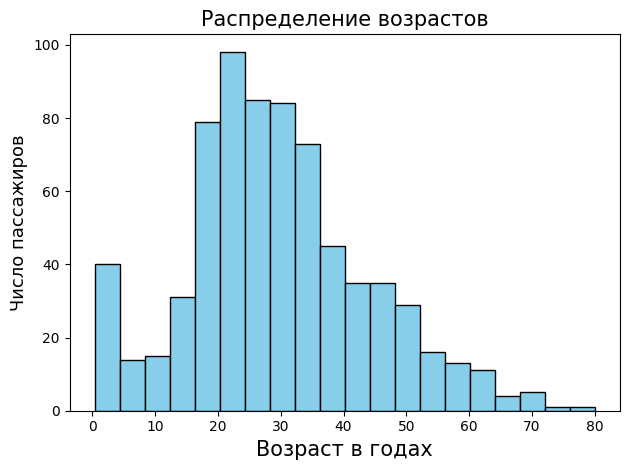

In [7]:
import matplotlib.pyplot as plt
plt.hist(df['Age'], bins=20, color='skyblue', edgecolor='black')
plt.title('Распределение возрастов', fontsize=15)
plt.xlabel('Возраст в годах', fontsize=15)
plt.ylabel('Число пассажиров', fontsize=13)
plt.tight_layout()
plt.show()

2. Постройте гистограммы распределения цен для пассажиров разных классов

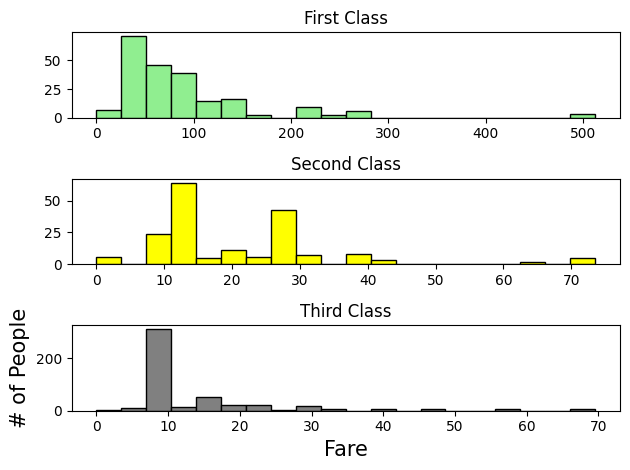

In [ ]:
figure, axes = plt.subplots(3,1)
axes[0].hist(df[df['Pclass'] == 1]['Fare'], bins=20, color='lightgreen', edgecolor='black')
axes[0].set_title('First Class')
axes[1].hist(df[df['Pclass'] == 2]['Fare'], bins=20, color='yellow', edgecolor='black')
axes[1].set_title('Second Class')
axes[2].hist(df[df['Pclass'] == 3]['Fare'], bins=20, color='grey', edgecolor='black')
axes[2].set_title('Third Class')

plt.xlabel('Fare', fontsize=15)
plt.ylabel('# of People', fontsize=15)
plt.tight_layout()
plt.show()

3. Постройте зависимость цены от возраста пассажира

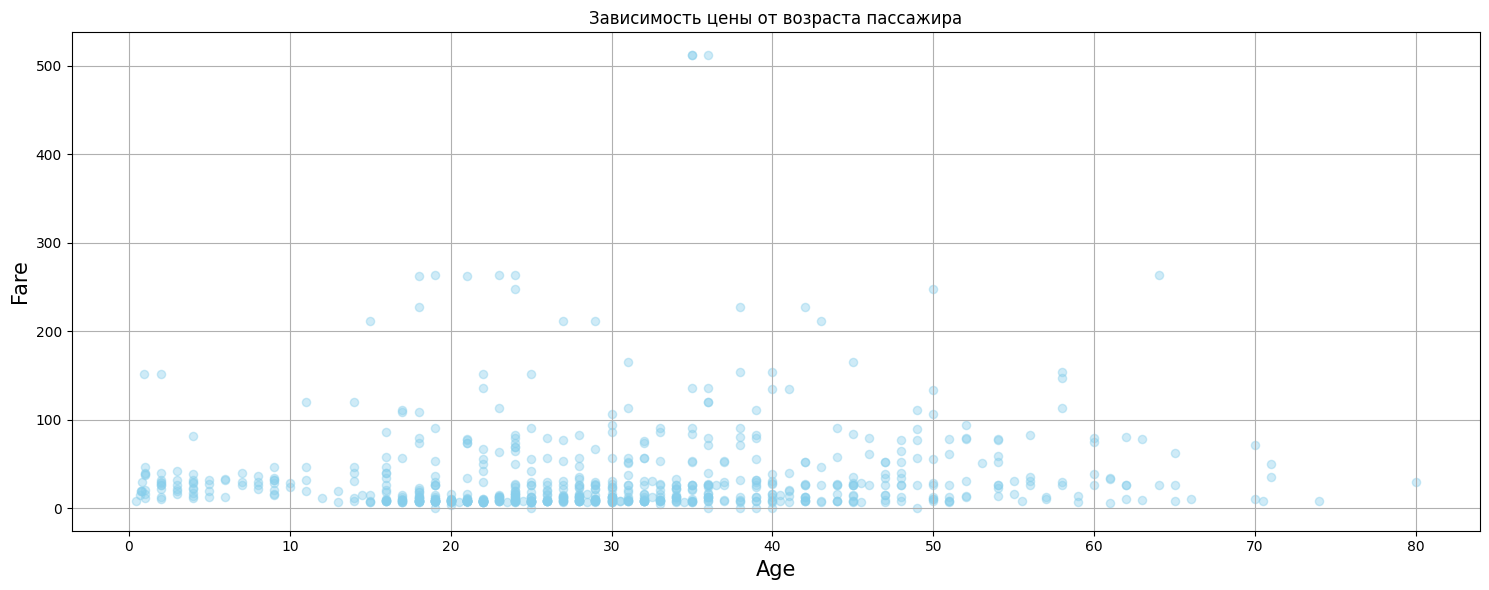

In [ ]:
plt.figure(figsize=(15, 6))
plt.scatter(df['Age'], df['Fare'], alpha=0.4, color='skyblue', s = 35)
plt.xlabel('Age', fontsize=15)
plt.ylabel('Fare', fontsize=15)
plt.title('Зависимость цены от возраста пассажира')
plt.tight_layout()
plt.grid()
plt.show()

4. Постройте box plot отображающий распределение цен на билеты в разных классах

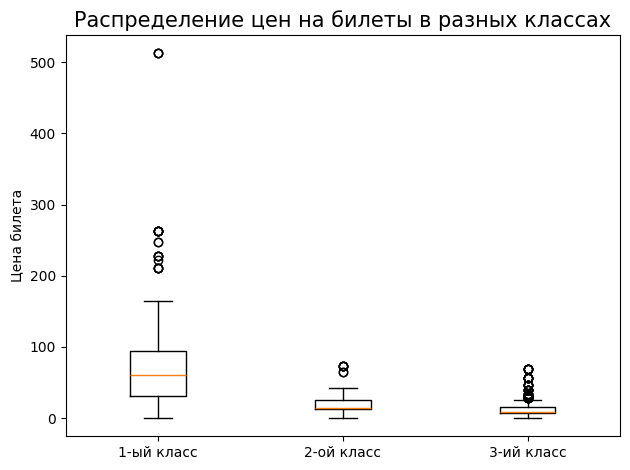

In [ ]:
data = [df[df['Pclass'] == 1]['Fare'], df[df['Pclass'] == 2]['Fare'], df[df['Pclass'] == 3]['Fare']]

plt.boxplot(data)
plt.xticks([1, 2, 3], ['1-ый класс', '2-ой класс', '3-ий класс'])
plt.title('Распределение цен на билеты в разных классах', fontsize=15)
plt.ylabel('Цена билета')
plt.tight_layout()
plt.show()

5. Визуализируйте распределение долей выживших среди мужчин, женщин и детей(до 16 лет)

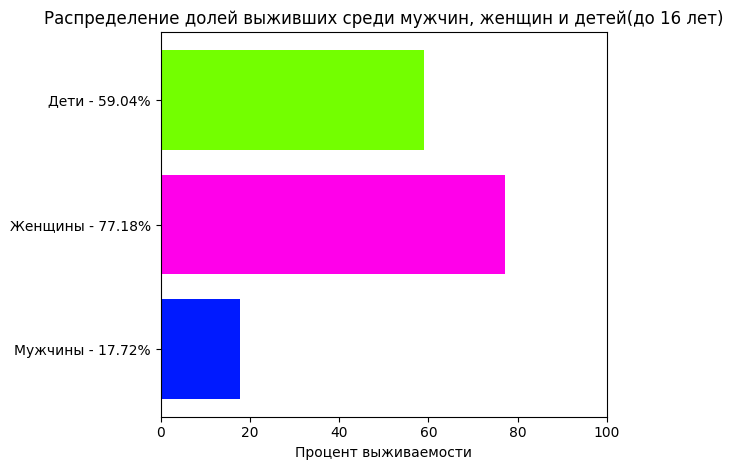

In [ ]:
# А куда нам деть людей 16, 17-летних? Они и не дети получается, и не взрослые
# Они в сделку не входят по условию получается, если молодые мужчины от 18 и женщины соответственно тоже?
is_child = df['Age'].lt(16)
is_men = (df['Sex'] == 'male') & (df['Age'] >= 18)
is_women = (df['Sex'] == 'female') & (df['Age'] >= 18)

survival_rate = [
    df[is_men]['Survived'].mean() * 100,
    df[is_women]['Survived'].mean() * 100,
    df[is_child]['Survived'].mean() * 100
]


categories = ['Мужчины', 'Женщины', 'Дети']
colors = ['#001aff', '#ff00ea', '#73ff00']
labels_with_percents = [f'Мужчины - {survival_rate[0]:.2f}%',
                        f'Женщины - {survival_rate[1]:.2f}%',
                        f'Дети - {survival_rate[2]:.2f}%']

plt.barh(labels_with_percents, survival_rate, color=colors)
plt.xlim(0, 100)
plt.title('Распределение долей выживших среди мужчин, женщин и детей(до 16 лет)')
plt.xlabel('Процент выживаемости')
plt.tight_layout()
plt.show()

6. Сравните плотности распределения возростов выживших и умерших пассажиров, сделайте выводы

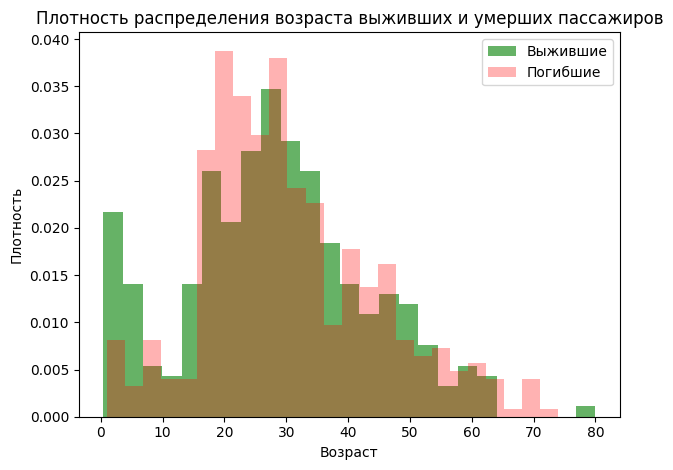

In [ ]:
is_alive = df['Survived'] == 1
is_dead = df['Survived'] == 0

plt.figure()
plt.hist(df[is_alive]['Age'].dropna(), bins=25, density=True, color='green', alpha=0.6, label='Выжившие')
plt.hist(df[is_dead]['Age'].dropna(), bins=25, density=True, color='red', alpha=0.3, label='Погибшие')
plt.title('Плотность распределения возраста выживших и умерших пассажиров')
plt.xlabel('Возраст')
plt.ylabel('Плотность')
plt.tight_layout()
plt.legend()
plt.show()

# Вывод: выживаемость детей (0-10 лет) значительно выше, в то время как пик погибших приходится на молодых людей 20-30 лет

7. Постройте круговую диаграмму отображающую выживаемость мужчин и женщин в разных классах обслуживания(визуализация должна быть интуитивно понятная без объяснений, женщины и мужчины соответствующих классов объеденены визуально в одну группу и 2 подгруппы)*

\* Задание на доп. балл